# 02 — Preprocessing and feature extraction

How raw trips become the labelled candidate table used by every model, with evidence for each decision.
Partitions: **train** for choosing parameters, **student_test** for confirmation. Evaluator-test data is not used.

Pipeline (all code in `pathsnap/`): load → per-trip UTM projection → track cleaning → per-observation labels
(training only) → candidate generation → 16 features.

In [1]:
# --- setup: find the repo, check data (works from any folder inside the repo) ---
import sys, pathlib
ROOT = pathlib.Path.cwd().resolve()
while not (ROOT / "pathsnap" / "config.py").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
if not (ROOT / "pathsnap" / "config.py").exists():
    raise RuntimeError("Run this notebook from inside the cloned repo (its notebooks/ folder).")
sys.path.insert(0, str(ROOT))
from pathsnap.reproduce import check_data, ensure_processed, models_ready
ensure_processed()                # builds data/processed/* if missing (~1 min)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pyproj import Geod, Transformer

from pathsnap.config import (PARTITIONS, PROCESSED_DIR, RESULTS_DIR, MAX_SPEED_MS, GAP_BREAK_S,
                             LABEL_MAX_DIST_M, CAND_RADIUS_M, CAND_K)
from pathsnap.data_processing.loader import list_trips, load_trip, utm_crs_for
from pathsnap.data_processing.clean import clean_track, flag_outliers
from pathsnap.data_processing.labels import label_track, monotone_align
from pathsnap.data_processing.geometry import point_segment_distance
from pathsnap.features.candidates import FEATURE_COLUMNS

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 40)
plt.rcParams["figure.dpi"] = 110

raw data OK: /run/media/amogh-herle/DATA/PESU/ML_LAB/HACKATHON/Student folder  {'train': 80, 'student_test': 10}
processed data OK: /run/media/amogh-herle/DATA/PESU/ML_LAB/HACKATHON/pathsnap/data/processed


## 1. Coordinate projection: fixed zone vs per-trip UTM

True path length of every track is measured on the WGS84 ellipsoid (`pyproj.Geod`) and compared with the planar length after projection.

In [2]:
geod = Geod(ellps="WGS84")
fixed = Transformer.from_crs("EPSG:4326", "EPSG:32632", always_xy=True)
rows = []
for p in PARTITIONS:
    for t in list_trips(p):
        trip = load_trip(t, p, with_route=False)
        tr = trip.track
        lon, lat = tr["lon"].to_numpy(), tr["lat"].to_numpy()
        true_m = geod.line_length(lon, lat)
        own = np.hypot(np.diff(tr["x"]), np.diff(tr["y"])).sum()
        fx, fy = fixed.transform(lon, lat)
        with np.errstate(invalid="ignore"):  # trip 57 projects to inf in zone 32N
            fixed_m = np.hypot(np.diff(fx), np.diff(fy)).sum()
        rows.append({"partition": p, "trip_id": t, "crs": trip.crs, "geodesic_km": true_m / 1000,
                     "err_per_trip_utm_pct": 100 * (own - true_m) / true_m,
                     "err_fixed_32N_pct": 100 * (fixed_m - true_m) / true_m if np.isfinite(fixed_m) else np.inf})
proj = pd.DataFrame(rows)
summary = proj.groupby("partition").agg(
    trips=("trip_id", "size"),
    per_trip_utm_max_abs_err_pct=("err_per_trip_utm_pct", lambda s: s.abs().max()),
    fixed_32N_median_abs_err_pct=("err_fixed_32N_pct", lambda s: s.replace(np.inf, np.nan).abs().median()),
    fixed_32N_max_abs_err_pct=("err_fixed_32N_pct", lambda s: s.replace(np.inf, np.nan).abs().max()),
    fixed_32N_infinite=("err_fixed_32N_pct", lambda s: np.isinf(s).sum()))
summary.round(3)

,trips,per_trip_utm_max_abs_err_pct,fixed_32N_median_abs_err_pct,fixed_32N_max_abs_err_pct,fixed_32N_infinite
partition,,,,,
student_test,10,0.040,6.873,38.358,0
train,80,0.084,1.759,232.586,1


In [3]:
proj.sort_values("err_fixed_32N_pct", key=lambda s: s.abs(), ascending=False).head(6).round(3)

,partition,trip_id,crs,geodesic_km,err_per_trip_utm_pct,err_fixed_32N_pct
46,train,00000057,EPSG:32617,23.842,0.084,inf
16,train,00000021,EPSG:32648,128.585,-0.006,232.586
34,train,00000042,EPSG:32651,97.883,-0.025,122.178
64,train,00000081,EPSG:32617,38.759,-0.024,121.720
19,train,00000025,EPSG:32614,24.235,-0.018,89.473
6,train,00000008,EPSG:32616,25.043,-0.038,72.951


Per-trip UTM keeps path length within a fraction of a percent of the true geodesic length on every trip; one fixed zone (32N, chosen because trip 1 is in Germany) distorts distant trips by large factors or fails outright.

## 2. Track cleaning

Cleaning flags rather than deletes (every observation must still get a prediction). Columns added for train trip 00000001:

In [4]:
t1 = load_trip("00000001", "train")
c1 = clean_track(t1.track)
c1.head(5)

,obs_idx,lon,lat,t,x,y,dt_prev,step_m,speed_ms,is_invalid,is_outlier,segment_id
0,0,8.595203,49.844053,1.0,470895.691450,5.521371e+06,NaN,NaN,NaN,False,False,0
1,1,8.595294,49.844441,2.0,470902.467086,5.521414e+06,1.0,43.632247,43.632247,False,False,0
2,2,8.595352,49.844883,3.0,470906.902420,5.521463e+06,1.0,49.319383,49.319383,False,False,0
3,3,8.595390,49.845379,4.0,470909.932156,5.521518e+06,1.0,55.214278,55.214278,False,False,0
4,4,8.595587,49.845750,5.0,470924.318267,5.521559e+06,1.0,43.612784,43.612784,False,False,0


### 2a. Choosing the outlier speed limit (train only)

In [5]:
rows = []
for t in list_trips("train"):
    tr = load_trip(t, "train", with_route=False).track
    x, y, tt = tr["x"].to_numpy(), tr["y"].to_numpy(), tr["t"].to_numpy()
    rows.append({"trip_id": t, "n_points": len(tr),
                 "flagged_at_50": int(flag_outliers(x, y, tt, max_speed=50).sum()),
                 "flagged_at_85": int(flag_outliers(x, y, tt, max_speed=MAX_SPEED_MS).sum())})
out = pd.DataFrame(rows)
print("total flagged at 50 m/s:", out.flagged_at_50.sum(), "| at 85 m/s:", out.flagged_at_85.sum(),
      "| out of", out.n_points.sum(), "train points")
out.assign(pct_50=lambda d: (100 * d.flagged_at_50 / d.n_points).round(1),
           pct_85=lambda d: (100 * d.flagged_at_85 / d.n_points).round(2)
           ).sort_values("flagged_at_50", ascending=False).head(8)

total flagged at 50 m/s: 1606 | at 85 m/s: 73 | out of 208417 train points


,trip_id,n_points,flagged_at_50,flagged_at_85,pct_50,pct_85
25,00000032,2464,855,0,34.7,0.00
0,00000001,1315,415,0,31.6,0.00
10,00000013,2580,136,66,5.3,2.56
18,00000024,801,48,0,6.0,0.00
35,00000043,2322,40,2,1.7,0.09
22,00000028,3565,21,0,0.6,0.00
45,00000055,2472,18,0,0.7,0.00
43,00000053,1304,8,0,0.6,0.00


At 50 m/s, two autobahn trips lose about a third of their points to false outliers. At 85 m/s only genuine jumps remain.

### 2b. Segments at time gaps

In [6]:
pts = {p: pd.read_parquet(PROCESSED_DIR / f"{p}_points.parquet") for p in PARTITIONS}
seg = pd.concat([d.groupby("trip_id")["segment_id"].nunique().rename("segments").to_frame().assign(partition=p)
                 for p, d in pts.items()])
print(f"gap threshold: {GAP_BREAK_S} s")
seg.groupby("partition")["segments"].describe()[["count", "mean", "50%", "max"]]

gap threshold: 30.0 s


,count,mean,50%,max
partition,,,,
student_test,10.0,1.2000,1.0,2.0
train,80.0,2.6625,1.0,38.0


## 3. Per-observation labels

### 3a. Why monotonic alignment: naive nearest route arc vs dynamic programming

On a trip whose route revisits arcs, the naive nearest-route-arc label jumps backwards along the route; the monotonic DP alignment cannot.

trip 00000008: 3093 points, 173 route arcs
backward jumps in route position  naive: 88 | DP: 0
points labelled differently: 719


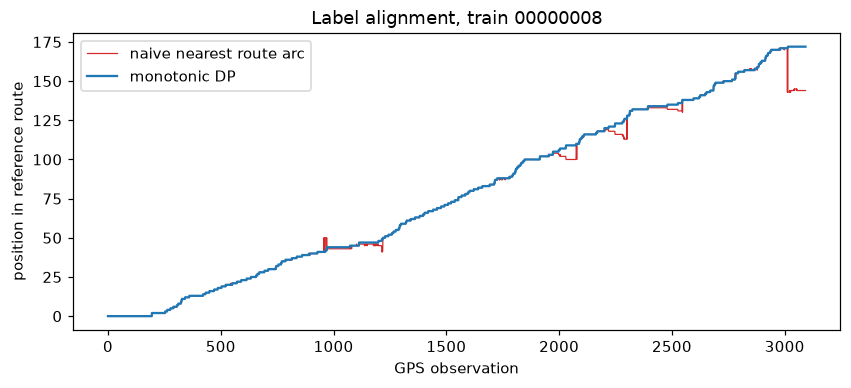

In [7]:
inv = pd.read_csv(RESULTS_DIR / "eda" / "inventory_train.csv", dtype={"trip_id": str})
loop_trip = inv.loc[inv.n_route_unique_arcs < inv.n_route_arcs, "trip_id"].iloc[0]
trip = load_trip(loop_trip, "train")
c = clean_track(trip.track)
good = ~(c.is_invalid | c.is_outlier)
px, py = c.loc[good, "x"].to_numpy(), c.loc[good, "y"].to_numpy()
u, v = trip.arcs.u.to_numpy()[trip.route], trip.arcs.v.to_numpy()[trip.route]
nx, ny = trip.nodes.x.to_numpy(), trip.nodes.y.to_numpy()
ax_, ay_, bx_, by_ = nx[u], ny[u], nx[v], ny[v]

naive = np.array([np.argmin(point_segment_distance(x, y, ax_, ay_, bx_, by_)[0]) for x, y in zip(px, py)])
dp = monotone_align(px, py, ax_, ay_, bx_, by_)
print(f"trip {loop_trip}: {len(px)} points, {len(trip.route)} route arcs")
print("backward jumps in route position  naive:", int((np.diff(naive) < 0).sum()), "| DP:", int((np.diff(dp) < 0).sum()))
print("points labelled differently:", int((naive != dp).sum()))
fig, ax = plt.subplots(figsize=(9, 3.5))
ax.plot(naive, lw=0.8, color="#d62728", label="naive nearest route arc")
ax.plot(dp, lw=1.5, color="#1f77b4", label="monotonic DP")
ax.set_xlabel("GPS observation"); ax.set_ylabel("position in reference route")
ax.set_title(f"Label alignment, train {loop_trip}"); ax.legend(); plt.show()

### 3b. Label distance and reliability

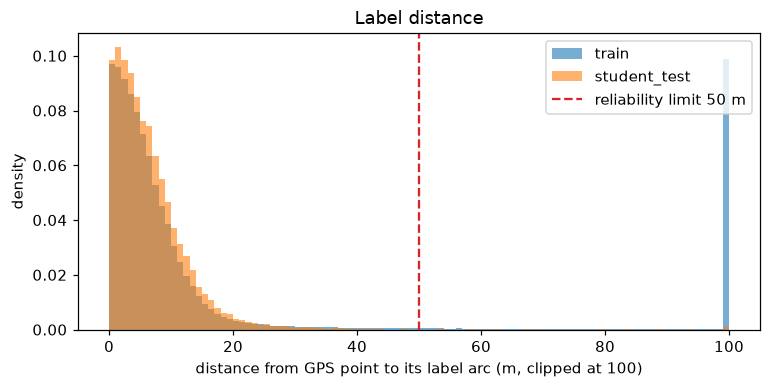

,train,student_test
points,208417.00,19160.00
labelled,208344.00,19160.00
reliable,185077.00,19133.00
reliable_pct,88.80,99.86
median_label_dist_m,5.68,5.27


In [8]:
fig, ax = plt.subplots(figsize=(8, 3.5))
for p, col in zip(PARTITIONS, ["#1f77b4", "#ff7f0e"]):
    d = pts[p].loc[pts[p].label_arc >= 0, "label_dist_m"]
    ax.hist(d.clip(upper=100), bins=100, alpha=0.6, density=True, color=col, label=p)
ax.axvline(LABEL_MAX_DIST_M, color="#d62728", ls="--", label=f"reliability limit {LABEL_MAX_DIST_M:.0f} m")
ax.set_xlabel("distance from GPS point to its label arc (m, clipped at 100)"); ax.set_ylabel("density")
ax.legend(); ax.set_title("Label distance"); plt.show()
pd.DataFrame({p: {"points": len(d), "labelled": int((d.label_arc >= 0).sum()),
                  "reliable": int(d.label_reliable.sum()),
                  "reliable_pct": round(100 * d.label_reliable.mean(), 2),
                  "median_label_dist_m": round(d.label_dist_m.median(), 2)} for p, d in pts.items()})

In [9]:
summ = pd.read_csv(RESULTS_DIR / "eda" / "preprocess_summary_train.csv", dtype={"trip_id": str})
summ["reliable_pct"] = 100 * summ.n_reliable / summ.n_points
summ.sort_values("reliable_pct")[["trip_id", "n_points", "n_outliers", "reliable_pct",
                                   "median_label_dist_m", "p95_label_dist_m", "suspect_reference"]].head(6).round(2)

,trip_id,n_points,n_outliers,reliable_pct,median_label_dist_m,p95_label_dist_m,suspect_reference
44,00000054,19313,0,10.56,140.09,210.05,True
26,00000033,5844,1,40.98,122.46,142.06,True
1,00000002,7243,0,88.02,5.77,242.36,False
53,00000066,4325,0,90.98,6.59,65.53,False
35,00000043,2322,2,92.72,11.00,70.26,False
64,00000081,3224,0,95.56,4.54,44.56,False


Trips 00000054 (parked-car GPS drift) and 00000033 (route and GPS disagree) are flagged `suspect_reference`; their far-off points are excluded from training through `label_reliable`.

## 4. Candidate generation: choosing radius and k (train sweep)

Produced by `python -m pathsnap.features.build --sweep`.

k                         1      2     4     8     12    16    20
partition    radius_m                                            
student_test 15        47.70  13.92  9.08  7.20  7.13  7.12  7.12
             25        46.02   9.30  3.94  1.53  1.37  1.35  1.35
             50        45.97   8.26  2.74  0.26  0.07  0.03  0.01
             75        45.97   8.26  2.74  0.26  0.07  0.03  0.01
             100       45.97   8.26  2.74  0.26  0.07  0.03  0.01
train        15        46.74  12.84  8.61  7.40  7.29  7.25  7.21
             25        44.92   9.34  4.37  2.67  2.45  2.39  2.34
             50        44.14   8.04  2.81  0.84  0.56  0.46  0.29
             75        44.14   8.04  2.81  0.84  0.56  0.46  0.29
             100       44.14   8.04  2.81  0.84  0.56  0.46  0.29

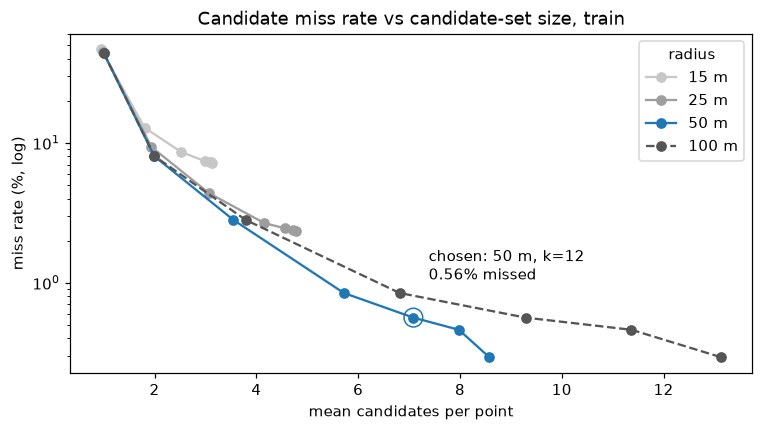

In [10]:
sweep = pd.read_csv(RESULTS_DIR / "eda" / "candidate_sweep.csv")
display((100 * sweep.pivot_table(index=["partition", "radius_m"], columns="k", values="miss_rate")).round(2))
tr = sweep[sweep.partition == "train"]
fig, ax = plt.subplots(figsize=(8, 4))
for r, col in zip([15, 25, 50, 100], ["#c7c7c7", "#9e9e9e", "#1f77b4", "#555555"]):
    s = tr[tr.radius_m == r]
    ax.plot(s.mean_cand, 100 * s.miss_rate, marker="o", color=col, ls="--" if r == 100 else "-", label=f"{r} m")
ch = tr[(tr.radius_m == CAND_RADIUS_M) & (tr.k == CAND_K)].iloc[0]
ax.scatter([ch.mean_cand], [100 * ch.miss_rate], s=150, facecolors="none", edgecolors="#1f77b4")
ax.annotate(f"chosen: {CAND_RADIUS_M:.0f} m, k={CAND_K}\n{100*ch.miss_rate:.2f}% missed",
            (ch.mean_cand, 100 * ch.miss_rate), xytext=(10, 25), textcoords="offset points")
ax.set_yscale("log"); ax.set_xlabel("mean candidates per point"); ax.set_ylabel("miss rate (%, log)")
ax.set_title("Candidate miss rate vs candidate-set size, train"); ax.legend(title="radius"); plt.show()

Radii above 50 m reach the same miss rate with more candidates (labels are within 50 m by construction). k = 1 misses ~44% because two-way streets are stored as two arcs with identical geometry.

## 5. Features

16 features per (GPS point, candidate arc), all computed from GPS + road network only.

In [11]:
cand = pd.read_parquet(PROCESSED_DIR / "train_candidates.parquet",
                       columns=["trip_id", "pt", "label", "label_reliable"] + FEATURE_COLUMNS)
cand = cand[cand.label_reliable]
print(f"{len(cand):,} reliable train rows, {cand[['trip_id','pt']].drop_duplicates().shape[0]:,} GPS points, "
      f"positive rate {cand.label.mean():.3f}")
cand.groupby("label")[FEATURE_COLUMNS].mean().T.rename(columns={0: "wrong arc (0)", 1: "true arc (1)"}).round(3)

1,311,281 reliable train rows, 185,077 GPS points, positive rate 0.140


label,wrong arc (0),true arc (1)
dist_m,22.363,6.341
dist_rank,4.182,0.254
dist_gap_to_best,16.997,0.657
n_cand,9.650,7.057
heading_diff_deg,96.735,31.617
heading_known,0.983,0.985
arc_len_m,84.309,209.108
proj_frac,0.497,0.501
speed_ms,13.312,14.446
dt_prev,2.737,2.042


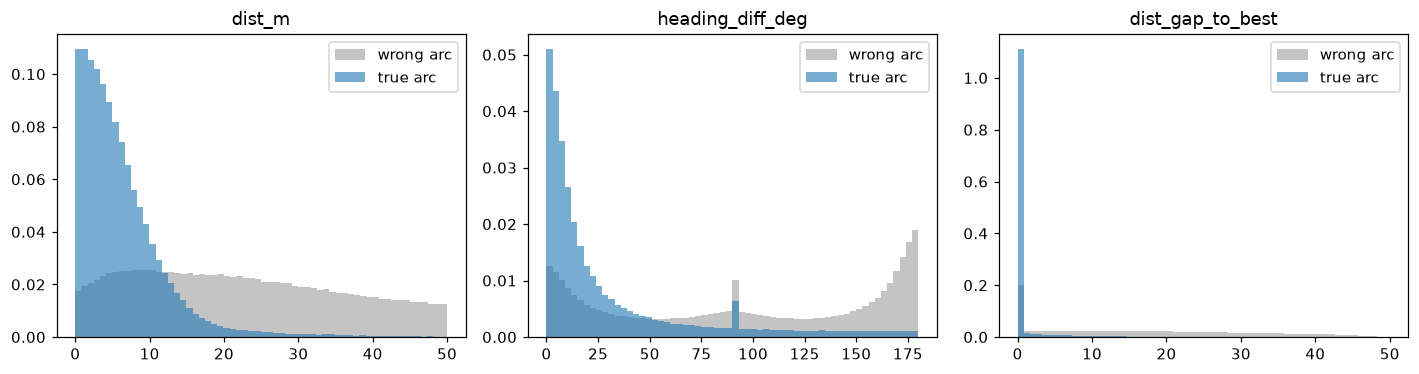

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.5))
for ax, f, clip in zip(axes, ["dist_m", "heading_diff_deg", "dist_gap_to_best"], [60, 180, 60]):
    for lab, col in [(0, "#9e9e9e"), (1, "#1f77b4")]:
        ax.hist(cand.loc[cand.label == lab, f].clip(upper=clip), bins=60, density=True, alpha=0.6,
                color=col, label="true arc" if lab else "wrong arc")
    ax.set_title(f); ax.legend()
plt.tight_layout(); plt.show()

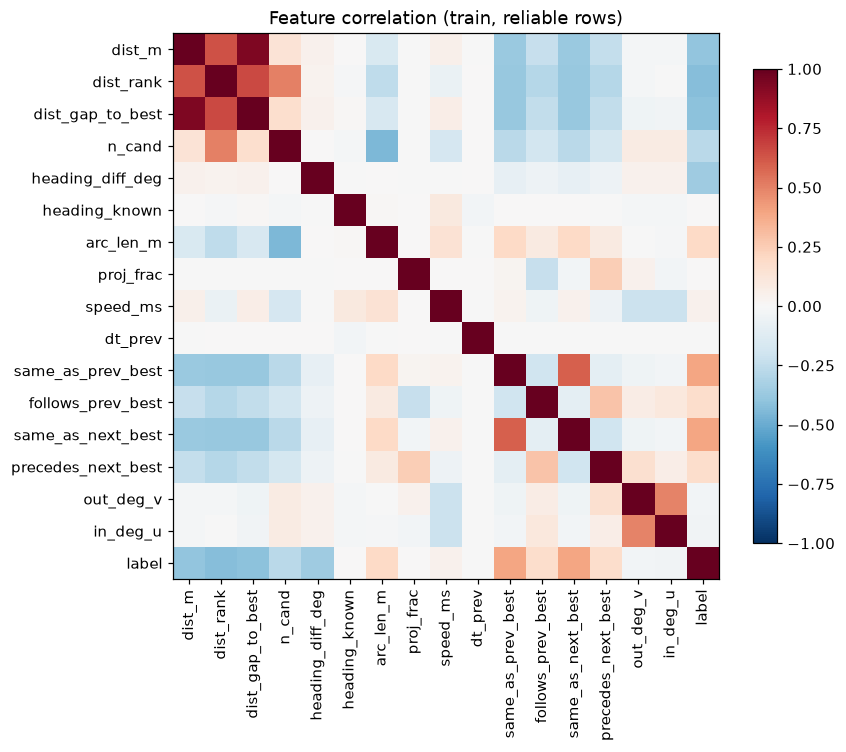

dist_rank            -0.427
dist_gap_to_best     -0.409
dist_m               -0.398
same_as_next_best     0.393
same_as_prev_best     0.391
heading_diff_deg     -0.355
n_cand               -0.269
arc_len_m             0.203
precedes_next_best    0.177
follows_prev_best     0.176
speed_ms              0.042
in_deg_u             -0.032
out_deg_v            -0.031
heading_known         0.005
proj_frac             0.003
dt_prev              -0.001
Name: label, dtype: float64

In [13]:
corr = cand[FEATURE_COLUMNS + ["label"]].corr()
fig, ax = plt.subplots(figsize=(8, 7))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)), corr.columns, rotation=90); ax.set_yticks(range(len(corr)), corr.columns)
fig.colorbar(im, shrink=0.8); ax.set_title("Feature correlation (train, reliable rows)"); plt.show()
corr["label"].drop("label").sort_values(key=abs, ascending=False).round(3)

In [14]:
nearest = cand.sort_values(["trip_id", "pt", "dist_m"]).groupby(["trip_id", "pt"]).head(1)
print(f"Baseline without learning - pick the nearest candidate: top-1 = {nearest.label.mean():.3f} (train)")

Baseline without learning - pick the nearest candidate: top-1 = 0.559 (train)


The nearest-arc baseline sets the bar any model must beat. Heading difference and the neighbour-continuity flags carry the information distance cannot (direction of travel on two-way streets, consistency over time).

Output of this stage: `data/processed/<partition>_candidates.parquet`, consumed by `03_model_comparison.ipynb`.